# Train — ConvNeXt-Tiny

Trains and evaluates ConvNeXt-Tiny with the tuned hyperparameters in `ARCH_HYPERPARAMS["convnext_tiny"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["convnext_tiny"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ConvNeXt-Tiny: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ConvNeXt-Tiny: micro batch = 8, accumulation steps = 1 (effective batch size ≈ 8, target = 8)
Train: 947 | Val: 229 | Test: 567


## Model

In [3]:
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
model.avgpool = nn.AdaptiveMaxPool2d(1)  # global max pooling instead of average pooling
# classifier is (LayerNorm, Flatten, Linear); only the Linear layer is replaced.
in_f = model.classifier[2].in_features
model.classifier[2] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ConvNeXt-Tiny] Epoch   1/100 | LR: 6.78e-05 | train loss 0.8773 acc 0.672 | val loss 0.6124 acc 0.734 *


[ConvNeXt-Tiny] Epoch   2/100 | LR: 6.78e-05 | train loss 0.6245 acc 0.770 | val loss 0.5624 acc 0.755 *


[ConvNeXt-Tiny] Epoch   3/100 | LR: 6.78e-05 | train loss 0.4479 acc 0.816 | val loss 0.7170 acc 0.672


[ConvNeXt-Tiny] Epoch   4/100 | LR: 6.78e-05 | train loss 0.2960 acc 0.890 | val loss 0.6572 acc 0.790


[ConvNeXt-Tiny] Epoch   5/100 | LR: 6.78e-05 | train loss 0.3007 acc 0.897 | val loss 0.6217 acc 0.773


...

[ConvNeXt-Tiny] Epoch   8/100 | LR: 6.78e-05 | train loss 0.0267 acc 0.993 | val loss 0.7190 acc 0.803


[ConvNeXt-Tiny] Epoch   9/100 | LR: 6.78e-05 | train loss 0.1440 acc 0.952 | val loss 0.8346 acc 0.773


[ConvNeXt-Tiny] Epoch  10/100 | LR: 6.78e-05 | train loss 0.0676 acc 0.977 | val loss 0.6806 acc 0.812


[ConvNeXt-Tiny] Epoch  11/100 | LR: 6.78e-05 | train loss 0.0200 acc 0.994 | val loss 0.7526 acc 0.799


[ConvNeXt-Tiny] Epoch  12/100 | LR: 6.78e-05 | train loss 0.0105 acc 0.997 | val loss 0.7357 acc 0.843

[ConvNeXt-Tiny] No val loss improvement for 10 epochs, stopping at epoch 12.

[ConvNeXt-Tiny] Restored best checkpoint (val loss = 0.5624)


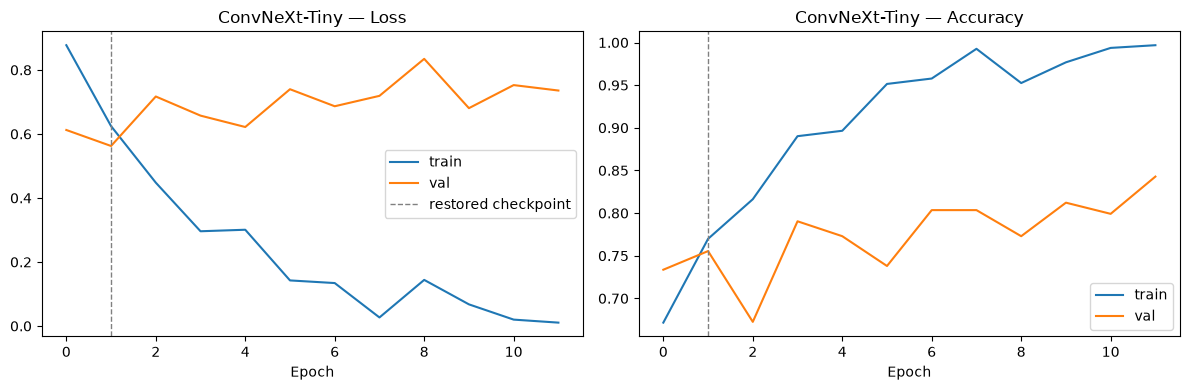

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ConvNeXt-Tiny", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ConvNeXt-Tiny")

## Evaluate on the test set

[ConvNeXt-Tiny] Test accuracy: 0.843


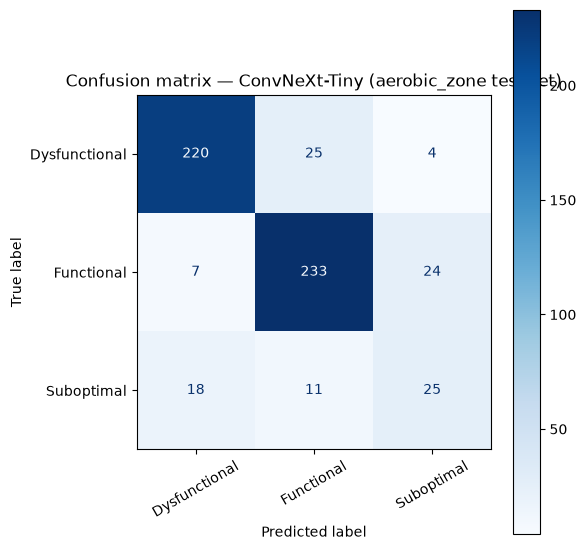

               precision    recall  f1-score   support

Dysfunctional      0.898     0.884     0.891       249
   Functional      0.866     0.883     0.874       264
   Suboptimal      0.472     0.463     0.467        54

     accuracy                          0.843       567
    macro avg      0.745     0.743     0.744       567
 weighted avg      0.843     0.843     0.843       567



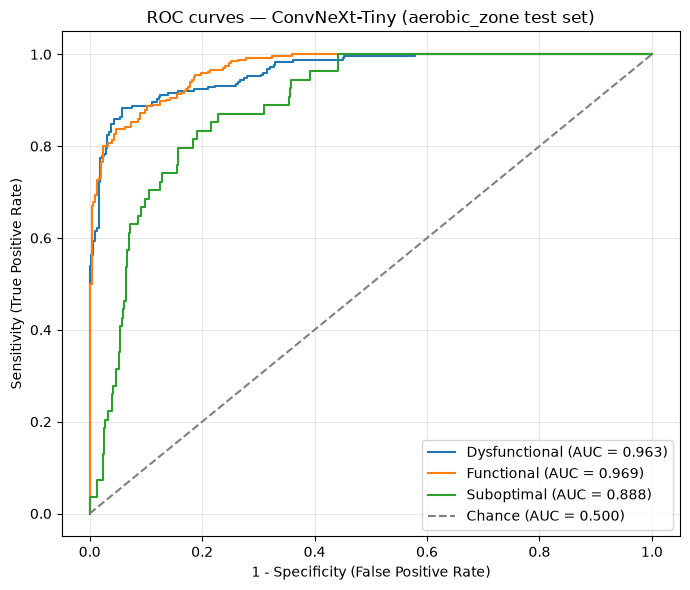

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.963
  Functional     : 0.969
  Suboptimal     : 0.888

Mean AUC (over 3/3 classes with test examples): 0.940


(np.float64(0.8430335097001763),
 {'Dysfunctional': 0.9628198327902807,
  'Functional': 0.9688343834383438,
  'Suboptimal': 0.887517146776406})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ConvNeXt-Tiny", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ConvNeXt-Tiny", "convnext_tiny")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_convnext_tiny_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_noaug/aerobic_zone_convnext_tiny_chronological.pt
